# Chapter 6 — Advanced Logistic Regression and Extensions

**Book:** *scikit-learn Cookbook, Third Edition* — John Sukup (2025), Chapter 6.

This notebook studies the methods presented in the chapter through runnable Python examples, brief explanations of the underlying ideas, model diagnostics and interpretations of the outputs. Explanatory text is original; code samples are book-aligned demonstrations rather than a verbatim transcript of every recipe.

Run the cells in order in Google Colab.

In [1]:
import sklearn, numpy as np
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


## 1. Binary logistic regression

Logistic regression is a classification model that estimates class probabilities through a logistic link. Its name comes from the mathematical regression formulation, even though it is frequently used for classification.

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
X,y=load_breast_cancer(return_X_y=True)
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.25,stratify=y,random_state=42)
clf=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)).fit(Xtr,ytr)
print('Accuracy:',round(accuracy_score(yte,clf.predict(Xte)),3))
print('First probabilities:',clf.predict_proba(Xte[:4]).round(3))

Accuracy: 0.986
First probabilities: [[0.031 0.969]
 [1.    0.   ]
 [0.441 0.559]
 [0.061 0.939]]


**Interpretation**

The probability pairs for each sample add to one. The classifier chooses a label from these probabilities, and accuracy measures the fraction of held-out examples classified correctly.

## 2. Decision threshold and confusion matrix

The default decision threshold is often 0.5 for binary classification. Changing it shifts the trade-off between missed positives and false alarms.

In [3]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score
p=clf.predict_proba(Xte)[:,1]
for threshold in [.3,.5,.7]:
    pred=(p>=threshold).astype(int)
    print('threshold',threshold,'confusion matrix',confusion_matrix(yte,pred).tolist(),'precision',round(precision_score(yte,pred),3),'recall',round(recall_score(yte,pred),3))

threshold 0.3 confusion matrix [[50, 3], [0, 90]] precision 0.968 recall 1.0
threshold 0.5 confusion matrix [[52, 1], [1, 89]] precision 0.989 recall 0.989
threshold 0.7 confusion matrix [[52, 1], [6, 84]] precision 0.988 recall 0.933


**Interpretation**

A lower threshold generally classifies more observations as positive, increasing recall but potentially generating additional false positives. The preferred threshold depends on the cost of each error type.

## 3. Multiclass classification

Logistic regression can distinguish more than two classes by learning decision boundaries across categories. Scaling helps make optimization more stable.

In [4]:
from sklearn.datasets import load_iris
from sklearn.metrics import classification_report
Xi,yi=load_iris(return_X_y=True)
A,B,c,d=train_test_split(Xi,yi,test_size=.3,random_state=3,stratify=yi)
multi=make_pipeline(StandardScaler(),LogisticRegression(max_iter=3000)).fit(A,c)
print(classification_report(d,multi.predict(B),target_names=load_iris().target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.87      0.87      0.87        15
   virginica       0.87      0.87      0.87        15

    accuracy                           0.91        45
   macro avg       0.91      0.91      0.91        45
weighted avg       0.91      0.91      0.91        45



**Interpretation**

Precision and recall are shown separately for each flower species, so strong overall performance does not hide a weak class. The support column identifies how many test samples belong to each class.

## 4. Regularized logistic regression

The inverse regularization strength C controls how strongly logistic-regression coefficients are penalized: smaller C means stronger regularization.

In [5]:
from sklearn.model_selection import cross_val_score
for C in [.01,.1,1,10]:
    m=make_pipeline(StandardScaler(),LogisticRegression(C=C,max_iter=2000))
    scores=cross_val_score(m,Xtr,ytr,cv=5,scoring='accuracy')
    print(f'C={C:<5} mean CV accuracy={scores.mean():.3f}')

C=0.01  mean CV accuracy=0.951
C=0.1   mean CV accuracy=0.977
C=1     mean CV accuracy=0.969
C=10    mean CV accuracy=0.965


**Interpretation**

Cross-validation scores indicate whether increasing model flexibility is helpful for the data. Selecting the largest C automatically is not justified; an intermediate penalty can generalize just as well.

## 5. Multilabel classification

In multilabel classification, each observation may have several correct labels. One-vs-rest modeling fits an independent binary classifier for each label.

In [6]:
from sklearn.datasets import make_multilabel_classification
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score
Xm,ym=make_multilabel_classification(n_samples=250,n_features=20,n_classes=4,n_labels=2,random_state=42)
A,B,c,d=train_test_split(Xm,ym,test_size=.25,random_state=42)
ml=OneVsRestClassifier(make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))).fit(A,c)
pr=ml.predict(B)
print('True labels for first sample:',d[0])
print('Predicted labels:',pr[0])
print('Micro F1:',round(f1_score(d,pr,average='micro'),3))

True labels for first sample: [1 0 0 0]
Predicted labels: [1 0 0 0]
Micro F1: 0.72


**Interpretation**

The output is a vector of zeros and ones, not a single category. Micro-averaged F1 summarizes precision and recall across all label decisions.

## 6. ROC AUC and probability calibration

ROC AUC evaluates the ranking of positive examples across possible thresholds. Predicted probabilities are more useful when their values reflect observed frequencies.

In [7]:
from sklearn.metrics import roc_auc_score, brier_score_loss
print('ROC AUC:',round(roc_auc_score(yte,p),3))
print('Brier score:',round(brier_score_loss(yte,p),3))
print('Mean predicted positive probability:',round(p.mean(),3))
print('Observed positive proportion:',round(yte.mean(),3))

ROC AUC: 0.998
Brier score: 0.018
Mean predicted positive probability: 0.616
Observed positive proportion: 0.629


**Interpretation**

ROC AUC summarizes discrimination, while the Brier score penalizes inaccurate probabilities. A strong ranking score does not automatically guarantee perfect probability calibration.

## 7. Probability distributions and decision boundaries

Logistic regression converts a weighted combination of features into a probability using the sigmoid function. The boundary is determined by the decision threshold, rather than by the predicted class label alone. This example uses two Iris measurements so the relationship between probabilities and geometry is easier to see.

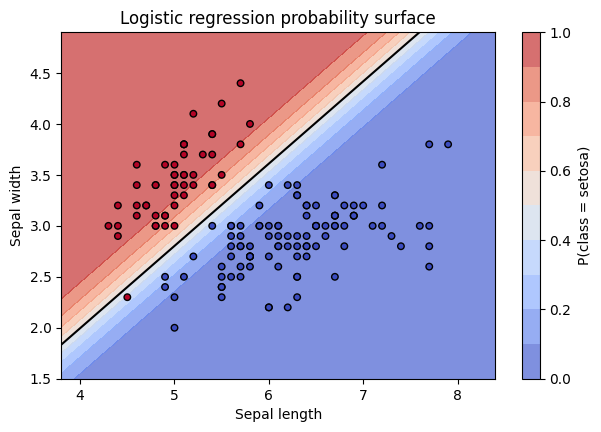

Training accuracy: 0.993


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
iris = load_iris()
X_two = iris.data[:,:2]
y_binary = (iris.target == 0).astype(int)
prob_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_two,y_binary)
xx,yy=np.meshgrid(np.linspace(X_two[:,0].min()-.5,X_two[:,0].max()+.5,110),np.linspace(X_two[:,1].min()-.5,X_two[:,1].max()+.5,110))
zz=prob_model.predict_proba(np.c_[xx.ravel(),yy.ravel()])[:,1].reshape(xx.shape)
fig,ax=plt.subplots(figsize=(7,4.5))
ct=ax.contourf(xx,yy,zz,levels=np.linspace(0,1,11),cmap='coolwarm',alpha=.7)
ax.contour(xx,yy,zz,levels=[.5],colors='black',linewidths=1.5)
ax.scatter(X_two[:,0],X_two[:,1],c=y_binary,cmap='coolwarm',edgecolor='k',s=22)
fig.colorbar(ct,ax=ax,label='P(class = setosa)')
ax.set(xlabel='Sepal length',ylabel='Sepal width',title='Logistic regression probability surface')
plt.show()
print('Training accuracy:', round(prob_model.score(X_two,y_binary),3))

**Interpretation**

The background represents predicted probability rather than a hard category. The black line marks the 0.5 threshold where the predicted class changes. The smooth transition shows why predicted probabilities contain more information than labels alone. Since the model is fitted and evaluated on the same dataset here, the reported accuracy is descriptive, not a held-out performance estimate.

## 8. Multiclass confusion matrix and per-class errors

Accuracy by itself can hide confusion between specific categories. A confusion matrix puts actual labels on rows and predicted labels on columns, allowing errors to be inspected separately for every class.

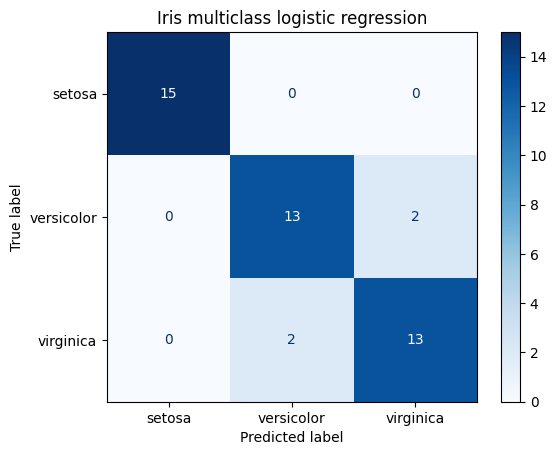

Balanced accuracy: 0.911


In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, balanced_accuracy_score
from sklearn.model_selection import train_test_split
I_X,I_y=iris.data,iris.target
I_A,I_B,I_c,I_d=train_test_split(I_X,I_y,test_size=.3,random_state=3,stratify=I_y)
cm_display=ConfusionMatrixDisplay.from_estimator(multi,I_B,I_d,display_labels=iris.target_names,cmap='Blues',values_format='d')
cm_display.ax_.set_title('Iris multiclass logistic regression')
plt.show()
print('Balanced accuracy:',round(balanced_accuracy_score(I_d,multi.predict(I_B)),3))

**Interpretation**

Values on the diagonal indicate correctly predicted samples. Off-diagonal entries reveal which Iris species are mixed up. Balanced accuracy averages recall over the classes, so it is useful when the class frequencies are uneven.

## 9. Cross-validated precision, recall, and F1

A single train/test split can vary depending on which examples fall into the test set. Stratified cross-validation makes the evaluation less dependent on one split while preserving class proportions.

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, f1_score
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
model_cv=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000))
from sklearn.datasets import load_breast_cancer
XC,yC=load_breast_cancer(return_X_y=True)
cv_result=cross_validate(model_cv,XC,yC,cv=cv,scoring=['accuracy','precision','recall','f1'])
for metric in ['accuracy','precision','recall','f1']:
    values=cv_result['test_'+metric]
    print(f'{metric}: mean={values.mean():.3f}, std={values.std():.3f}')

accuracy: mean=0.974, std=0.017
precision: mean=0.968, std=0.029
recall: mean=0.992, std=0.011
f1: mean=0.979, std=0.013


**Interpretation**

The mean summarizes performance across the five validation folds, and the standard deviation shows how much the result varies across those partitions. Looking at precision and recall alongside accuracy helps identify whether one error type is more common.

## 10. Probability calibration plot

A classifier can rank samples well without producing perfectly calibrated probabilities. A calibration curve compares predicted likelihoods with the fraction of cases that are positive within probability bins.

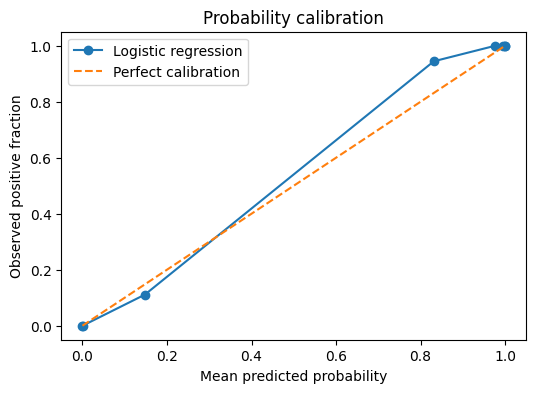

Number of populated bins: 8


In [11]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import RocCurveDisplay
observed, predicted=calibration_curve(yte,p,n_bins=8,strategy='quantile')
fig,ax=plt.subplots(figsize=(6,4))
ax.plot(predicted,observed,marker='o',label='Logistic regression')
ax.plot([0,1],[0,1],'--',label='Perfect calibration')
ax.set(xlabel='Mean predicted probability',ylabel='Observed positive fraction',title='Probability calibration')
ax.legend();plt.show()
print('Number of populated bins:',len(predicted))

**Interpretation**

Points near the dashed diagonal indicate probabilities that agree with observed frequencies. Departures may reflect sampling variability or systematic miscalibration; the plot should be interpreted alongside the test-set size and the Brier score.

## 11. Logistic regression coefficients and odds ratios

Coefficients describe changes in log-odds for a one-unit increase in a predictor while the other variables stay fixed. Exponentiating a coefficient gives the corresponding odds ratio. Standardization makes the numerical magnitude of coefficients easier to compare across differently measured features.

In [12]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
cancer=load_breast_cancer()
coef_pipe=make_pipeline(StandardScaler(),LogisticRegression(max_iter=3000))
coef_pipe.fit(cancer.data,cancer.target)
coef=coef_pipe.named_steps['logisticregression'].coef_[0]
for i in np.argsort(np.abs(coef))[-6:][::-1]:
    print(f'{cancer.feature_names[i]:30s} coefficient={coef[i]:+.3f} odds ratio={np.exp(coef[i]):.3f}')

worst texture                  coefficient=-1.321 odds ratio=0.267
radius error                   coefficient=-1.289 odds ratio=0.275
worst radius                   coefficient=-1.027 odds ratio=0.358
area error                     coefficient=-0.999 odds ratio=0.368
worst area                     coefficient=-0.995 odds ratio=0.370
mean concave points            coefficient=-0.963 odds ratio=0.382


**Interpretation**

The largest coefficients identify variables with substantial influence in this fitted linear decision rule. Odds ratios above one correspond to an increase in the odds of class 1; below one corresponds to a decrease. Correlated predictors can make individual coefficients unstable, so these values should not be interpreted as causal effects.

## 12. Predicting probabilities versus class labels

Binary classification produces two outputs: an estimated probability and a label obtained by applying a threshold. The probability indicates confidence in the positive class, while the label is a decision made using that estimate.

In [13]:
from sklearn.model_selection import train_test_split
Xa,Xb,ya,yb=train_test_split(cancer.data,cancer.target,stratify=cancer.target,test_size=.25,random_state=27)
pr_model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=3000)).fit(Xa,ya)
probs=pr_model.predict_proba(Xb[:8]); labels=pr_model.predict(Xb[:8])
for index,(pair,label,true) in enumerate(zip(probs,labels,yb[:8]),1):
    print(f'Sample {index}: P(0)={pair[0]:.3f}, P(1)={pair[1]:.3f}, predicted={label}, actual={true}')

Sample 1: P(0)=0.000, P(1)=1.000, predicted=1, actual=1
Sample 2: P(0)=0.006, P(1)=0.994, predicted=1, actual=1
Sample 3: P(0)=0.000, P(1)=1.000, predicted=1, actual=1
Sample 4: P(0)=0.011, P(1)=0.989, predicted=1, actual=1
Sample 5: P(0)=0.022, P(1)=0.978, predicted=1, actual=1
Sample 6: P(0)=0.000, P(1)=1.000, predicted=1, actual=1
Sample 7: P(0)=0.001, P(1)=0.999, predicted=1, actual=1
Sample 8: P(0)=1.000, P(1)=0.000, predicted=0, actual=0


**Interpretation**

Each row of class probabilities sums to one. An example with a probability close to 0.5 is less decisive than one near zero or one. Comparing the assigned labels with ground truth helps distinguish correct confidence from overconfident mistakes.

## 13. Decision thresholds and precision–recall trade-offs

The usual decision threshold of 0.5 is not always appropriate. When false negatives are costly, a lower threshold can improve recall, but it will often introduce additional false positives. Precision and recall must therefore be assessed jointly.

In [14]:
from sklearn.metrics import precision_score,recall_score,f1_score
p1=pr_model.predict_proba(Xb)[:,1]
for t in [0.2,0.35,0.5,0.65,0.8]:
    yp=(p1>=t).astype(int)
    print(f'threshold={t:.2f} precision={precision_score(yb,yp,zero_division=0):.3f} recall={recall_score(yb,yp):.3f} F1={f1_score(yb,yp):.3f}')

threshold=0.20 precision=0.938 recall=1.000 F1=0.968
threshold=0.35 precision=0.957 recall=1.000 F1=0.978
threshold=0.50 precision=0.967 recall=0.989 F1=0.978
threshold=0.65 precision=0.967 recall=0.978 F1=0.972
threshold=0.80 precision=0.977 recall=0.956 F1=0.966


**Interpretation**

Lower thresholds commonly increase the number of positive predictions and improve recall while reducing precision. The ideal operating point depends on the application rather than whichever threshold gives the best training accuracy.

## 14. Precision–recall curve and average precision

A precision–recall curve evaluates performance over a range of decision thresholds. It is especially informative when the positive class is less frequent because it focuses directly on the quality of positive predictions.

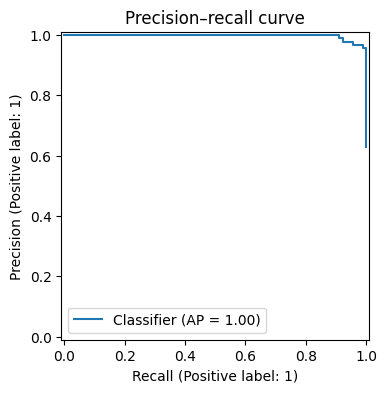

Average precision: 0.9975


In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay,average_precision_score
fig,ax=plt.subplots(figsize=(6,4))
PrecisionRecallDisplay.from_predictions(yb,p1,ax=ax)
ax.set_title('Precision–recall curve')
plt.show()
print('Average precision:',round(average_precision_score(yb,p1),4))

**Interpretation**

The curve summarizes the precision–recall trade-off as the decision threshold changes. Average precision gives a single summary, but the curve matters when a particular recall requirement is more important than the overall score.

## 15. Multiclass probabilities for individual observations

Multiclass logistic regression produces one probability for each possible class. The predicted class is the one with the highest probability, but the distribution across classes reveals ambiguity that an accuracy score alone cannot show.

In [16]:
from sklearn.datasets import load_iris
iris=load_iris()
ml=make_pipeline(StandardScaler(),LogisticRegression(max_iter=3000)).fit(iris.data,iris.target)
pro=ml.predict_proba(iris.data[[0,55,105]])
for i,row in zip([0,55,105],pro):
    print(f'Iris sample {i}:',dict(zip(iris.target_names,np.round(row,3))))

Iris sample 0: {np.str_('setosa'): np.float64(0.985), np.str_('versicolor'): np.float64(0.015), np.str_('virginica'): np.float64(0.0)}
Iris sample 55: {np.str_('setosa'): np.float64(0.022), np.str_('versicolor'): np.float64(0.87), np.str_('virginica'): np.float64(0.108)}
Iris sample 105: {np.str_('setosa'): np.float64(0.0), np.str_('versicolor'): np.float64(0.013), np.str_('virginica'): np.float64(0.987)}


**Interpretation**

The probability entries add to approximately one for each sample. A dominant class probability suggests that the model is confident in its decision; relatively similar probabilities indicate that nearby species are harder to distinguish.

## 16. One-vs-rest multiclass strategy

One-vs-rest trains a separate binary classifier for each category and selects the category receiving the strongest score. It allows binary decision methods to be extended to problems with multiple target classes.

In [17]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import cross_val_score,StratifiedKFold
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=11)
ovr=make_pipeline(StandardScaler(),OneVsRestClassifier(LogisticRegression(max_iter=3000)))
standard=make_pipeline(StandardScaler(),LogisticRegression(max_iter=3000))
for name,est in [('One-vs-rest',ovr),('Multinomial-style classifier',standard)]:
    s=cross_val_score(est,iris.data,iris.target,cv=cv)
    print(name,round(s.mean(),3),'+/-',round(s.std(),3))

One-vs-rest 0.927 +/- 0.065
Multinomial-style classifier 0.953 +/- 0.045


**Interpretation**

Both strategies can perform well on Iris, but the fitted objectives differ. Cross-validated scores show whether there is a meaningful practical difference on this dataset; the result does not establish that one strategy is superior in all cases.

## 17. L1 and L2 coefficient sparsity

L1 regularization penalizes the sum of absolute coefficient values and can set some coefficients exactly to zero. L2 penalizes the sum of squared coefficients and generally shrinks weights without forcing as many exact zeros.

In [18]:
for penalty in ['l1','l2']:
    p=make_pipeline(StandardScaler(),LogisticRegression(penalty=penalty,solver='liblinear',C=.1,max_iter=3000)).fit(Xa,ya)
    values=p.named_steps['logisticregression'].coef_[0]
    print(f'{penalty}: nonzero={np.count_nonzero(values)}/{len(values)}, test accuracy={p.score(Xb,yb):.3f}')

l1: nonzero=7/30, test accuracy=0.937
l2: nonzero=30/30, test accuracy=0.972


**Interpretation**

The number of nonzero coefficients shows how the regularization choice affects model complexity. A sparse L1 model may be easier to inspect, but feature selection by itself does not guarantee better predictions.

## 18. Cross-validating regularization strength

The C parameter is the inverse of regularization strength: smaller C means a stronger penalty. Grid search compares choices on validation folds and avoids selecting C from a single training fit.

In [19]:
from sklearn.model_selection import GridSearchCV
pipe=make_pipeline(StandardScaler(),LogisticRegression(max_iter=3000))
search=GridSearchCV(pipe,{'logisticregression__C':[0.01,.1,1,10,100]},cv=4,scoring='accuracy').fit(Xa,ya)
print('Best C:',search.best_params_['logisticregression__C'])
print('Validation accuracy:',round(search.best_score_,3))
print('Hold-out accuracy:',round(search.score(Xb,yb),3))

Best C: 1
Validation accuracy: 0.977
Hold-out accuracy: 0.972


**Interpretation**

The winning C is selected using only the training portion, keeping the held-out test set separate. Similar validation scores across several C values would indicate that the exact value is not especially critical for this dataset.

## 19. Multilabel output and label frequencies

In multilabel classification, each observation can belong to several classes simultaneously. Predictions are vectors of independent yes/no outcomes, and class-level frequencies help explain why some labels are easier to learn than others.

In [20]:
from sklearn.datasets import make_multilabel_classification
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import hamming_loss
Xmulti,ymulti=make_multilabel_classification(n_samples=350,n_features=20,n_classes=4,n_labels=2,random_state=14)
Xm_train,Xm_test,ym_train,ym_test=train_test_split(Xmulti,ymulti,test_size=.25,random_state=14)
mlabel=OneVsRestClassifier(LogisticRegression(max_iter=3000)).fit(Xm_train,ym_train)
pred=mlabel.predict(Xm_test)
print('Training label counts:',ym_train.sum(axis=0).tolist())
print('First five predictions:',pred[:5].tolist())
print('Hamming loss:',round(hamming_loss(ym_test,pred),3))

Training label counts: [132, 152, 157, 33]
First five predictions: [[1, 0, 0, 0], [1, 1, 0, 0], [1, 1, 0, 0], [0, 1, 0, 1], [0, 0, 1, 0]]
Hamming loss: 0.222


**Interpretation**

A predicted row can contain multiple ones, which is the defining feature of multilabel learning. Hamming loss measures the fraction of incorrect label positions and should not be confused with exact-match accuracy, which requires every label to be correct.

## 20. Micro and macro F1 for multilabel evaluation

Micro F1 pools all label decisions before computing a score, while macro F1 gives every class equal weight. Comparing both metrics helps reveal when common labels dominate aggregate performance.

In [21]:
from sklearn.metrics import f1_score,classification_report
print('Micro F1:',round(f1_score(ym_test,pred,average='micro',zero_division=0),3))
print('Macro F1:',round(f1_score(ym_test,pred,average='macro',zero_division=0),3))
print(classification_report(ym_test,pred,zero_division=0))

Micro F1: 0.75
Macro F1: 0.663
              precision    recall  f1-score   support

           0       0.71      0.74      0.73        47
           1       0.85      0.81      0.83        48
           2       0.74      0.82      0.78        49
           3       0.43      0.25      0.32        12

   micro avg       0.75      0.75      0.75       156
   macro avg       0.68      0.66      0.66       156
weighted avg       0.74      0.75      0.74       156
 samples avg       0.74      0.69      0.68       156



**Interpretation**

A gap between micro and macro F1 indicates that performance may be uneven across labels. The class-level report provides the precision, recall, and support needed to understand where the difference comes from.